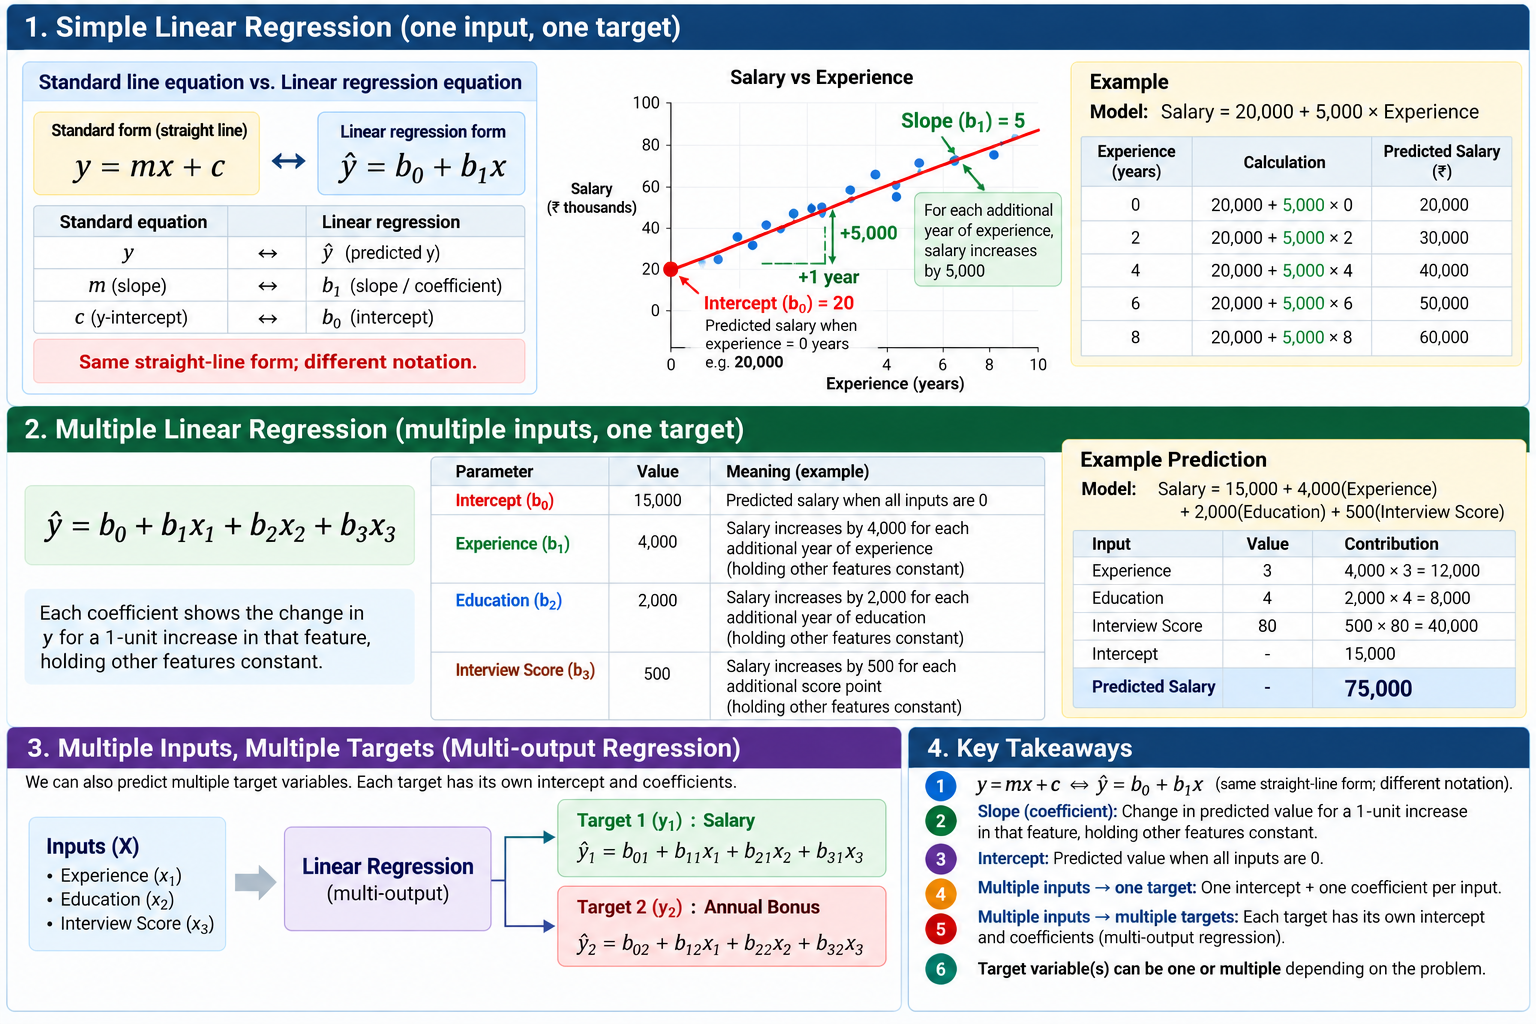

In [10]:
from sklearn.linear_model import LinearRegression
import numpy as np
# Input feature (X) and target (y)
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([25000, 30000, 35000, 40000, 45000])
print("Input features (X):", X)
print("Target values (y):", y)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Input features (X): [[1]
 [2]
 [3]
 [4]
 [5]]
Target values (y): [25000 30000 35000 40000 45000]
Shape of X: (5, 1)
Shape of y: (5,)


In [14]:
# Create the Linear Regression model
model = LinearRegression()
# Learn the best-fit line from the training data
model.fit(X, y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5000.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.16]


In [17]:
# 1. Check the learned equation
slope = model.coef_[0]
intercept = model.intercept_

print(f"Equation: salary = {intercept} + {slope} * experience")

Equation: salary = 20000.0 + 5000.0 * experience


In [15]:
# Predict salary for 6 years of experience
prediction = model.predict([[6]])

In [18]:
# 2. Calculate the prediction manually
experience = 6
manual_prediction = intercept + slope * experience

In [19]:
# 3. Compare manual and model predictions
model_prediction = model.predict([[experience]])[0]

print("Manual prediction:", manual_prediction)
print("Model prediction:", model_prediction)

assert abs(manual_prediction - model_prediction) < 1e-9
print("Validation passed!")

Manual prediction: 50000.0
Model prediction: 50000.0
Validation passed!


# Practical 1: Simple Linear Regression — Scikit-learn

Simple Linear Regression predicts a continuous target using one input feature by fitting a best-fit straight line.

 ## Key API Methods

| Code | Purpose |
|---|---|
| `LinearRegression()` | Creates the model |
| `model.fit(X, y)` | Learns from training data |
| `model.predict([[6]])` | Returns predictions as an array |
| `model.predict([[6]])[0]` | Extracts the first prediction |
| `model.coef_[0]` | Retrieves the slope for the first feature |
| `model.intercept_` | Retrieves the intercept |
| `X.shape` | Returns the number of rows and columns |

## Important Concepts

- `X` is a 2D feature matrix; `y` is a 1D target for single-target regression.
- `X.shape = (5, 1)` means 5 observations and 1 feature.
- `model.fit()` learns the line by minimizing the sum of squared errors.
- `model.predict()` applies the learned model to new input.
- Python indexing starts at `0`.
- `assert condition` verifies a condition and raises `AssertionError` if it is false.

```python
manual_prediction = model.intercept_ + model.coef_[0] * 6
model_prediction = model.predict([[6]])[0]

assert abs(manual_prediction - model_prediction) < 1e-9
print("Validation passed!")
```

Mean Squared Error (MSE) was not explicitly calculated in our code. However, LinearRegression().fit(X, y) uses the Ordinary Least Squares (OLS) method, which minimizes the sum of squared prediction errors. For a fixed dataset, minimizing the sum of squared errors is equivalent to minimizing MSE.

1. Where does MSE fit into our implementation?
Our existing code:
model = LinearRegression()model.fit(X, y)

During fit(), Scikit-learn learns the slope and intercept by minimizing:

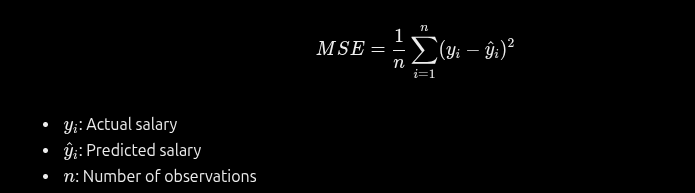

Important: MSE is the objective being minimized; we did not separately call an MSE function to display its value.

## Practical 2: Multiple Linear Regression with Scikit-learn

In [26]:
from sklearn.linear_model import LinearRegression
import numpy as np
# 1. Input features: experience, education years, interview score
X = np.array([
    [1, 12, 60],
    [2, 12, 65],
    [3, 16, 70],
    [4, 16, 80],
    [5, 18, 90]
])

# 2. Target: annual salary
y = np.array([30000, 35000, 50000, 60000, 75000])
print("Input features (X):", X.shape)
print("Target values (y):", y.shape)

Input features (X): (5, 3)
Target values (y): (5,)


In [28]:
# 3. Create and train the model
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -0.,2500.,1000.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[24.78, 2.16, 0.43]"


In [29]:
# 4. Predict salary for a new candidate
new_candidate = [[3, 16, 75]]
prediction = model.predict(new_candidate)[0]

# 5. Inspect the learned parameters
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Predicted salary:", prediction)

Coefficients: [-5.22720754e-12  2.50000000e+03  1.00000000e+03]
Intercept: -60000.0000000001
Predicted salary: 55000.0


In [30]:
# Calculate prediction using learned coefficients
manual_prediction = (
    model.intercept_
    + model.coef_[0] * 3
    + model.coef_[1] * 16
    + model.coef_[2] * 75
)

In [31]:
model_prediction = model.predict([[3, 16, 75]])[0]

print("Manual prediction:", manual_prediction)
print("Model prediction:", model_prediction)

assert abs(manual_prediction - model_prediction) < 1e-9
print("Validation passed!")

Manual prediction: 55000.0
Model prediction: 55000.0
Validation passed!


Remember: One feature → line; two features → plane; three or more features → hyperplane.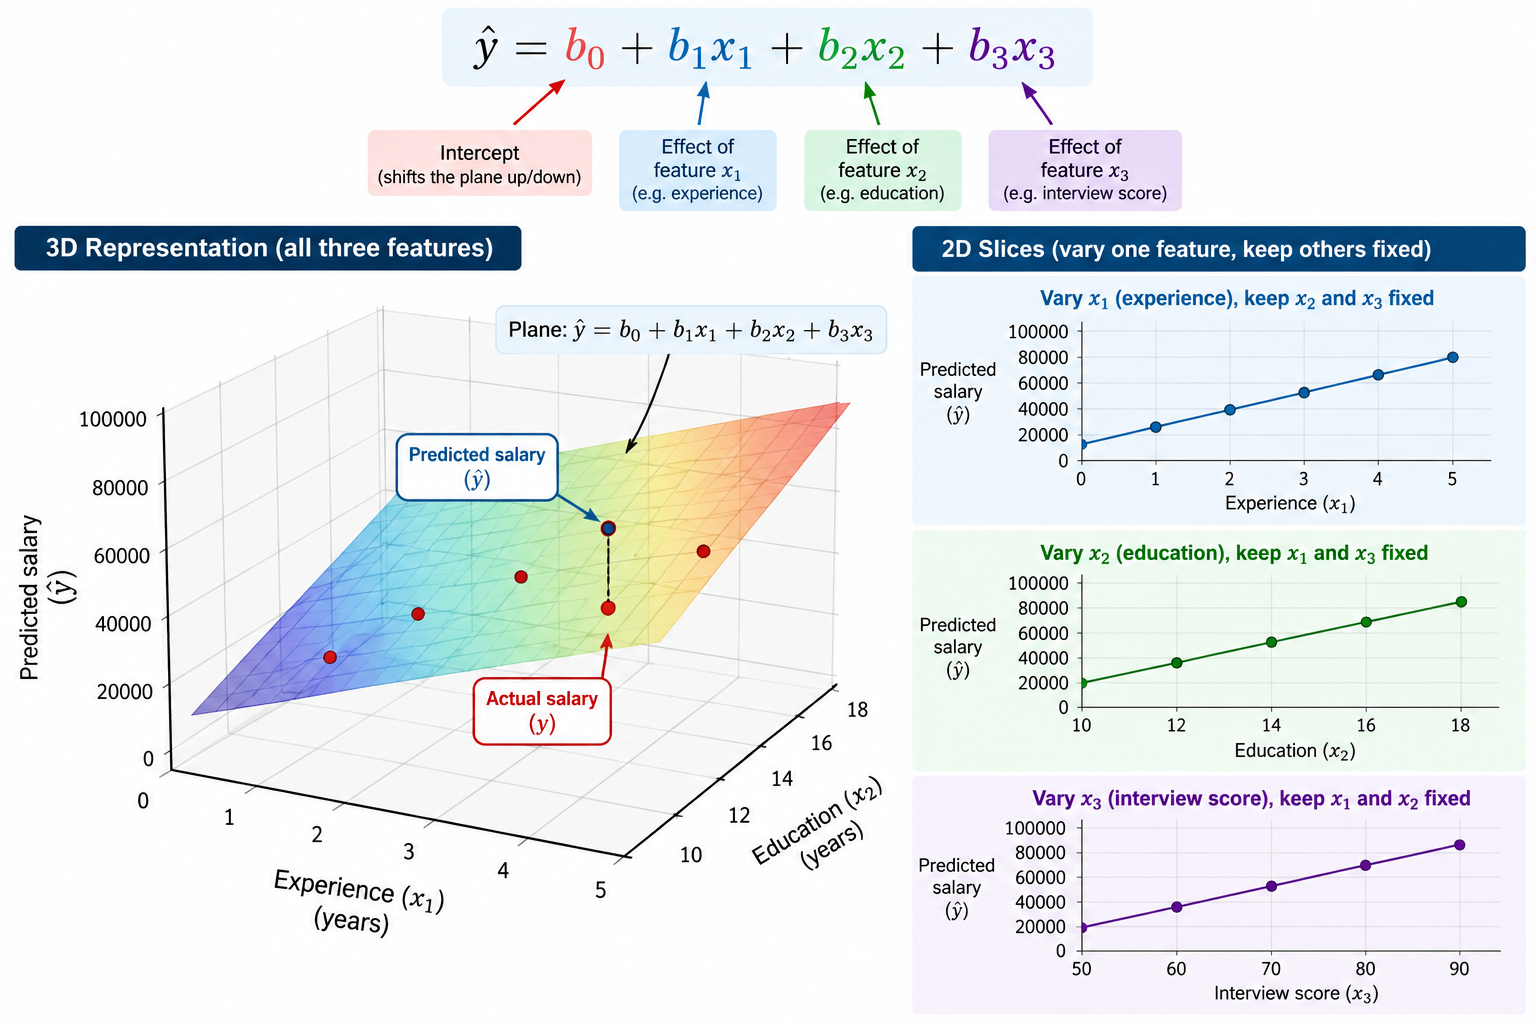

## Practical 3: Multi-Output Linear Regression
Objective: Learn how to predict multiple target variables using the same input features with Scikit-learn.

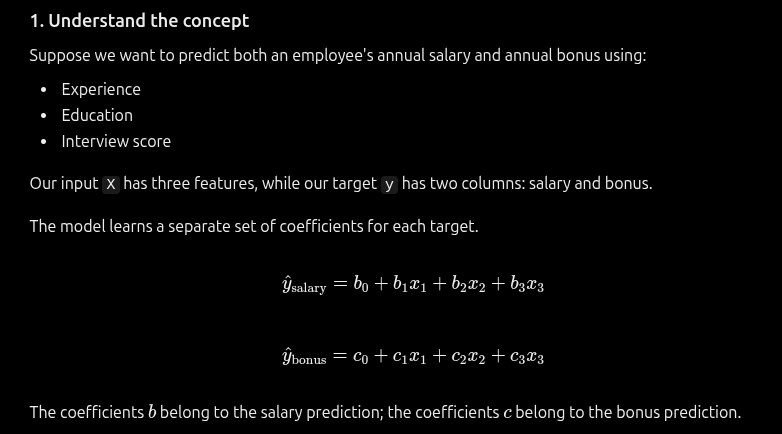

In [32]:
from sklearn.linear_model import LinearRegression
import numpy as np
# 1. Input features: experience, education years, interview score
X = np.array([
    [1, 12, 60],
    [2, 12, 65],
    [3, 16, 70],
    [4, 16, 80],
    [5, 18, 90]
])  
# 2. Two target columns: salary and annual bonus
y =np.array([
    [30000, 3000],
    [35000, 4000],
    [50000, 6000],
    [60000, 8000],
    [75000, 12000]
])
print("Input features (X):", X.shape)
print("Target values (y):", y.shape)

Input features (X): (5, 3)
Target values (y): (5, 2)


In [33]:
# 3. Create and train the model
model = LinearRegression()
model.fit(X, y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2, 3)","[[ -0. , 2500. , 1000. ], [-1269.23, 365.38, 384.62]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](2,)","[-60000. ,-23076.92]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[24.78, 2.16, 0.43]"


In [34]:
# 4. Predict both targets for a new candidate
new_candidate = [[3, 16, 75]]
predictions = model.predict(new_candidate)
print("Predicted salary:", predictions[0][0])
print("Predicted bonus:", predictions[0][1])

Predicted salary: 55000.0
Predicted bonus: 7807.6923076923085


In [35]:
# 5. Inspect learned parameters
print("Coefficient shape:", model.coef_.shape)
print("Intercept shape:", model.intercept_.shape)

# 6. Calculate training error for both targets
training_predictions = model.predict(X)

Coefficient shape: (2, 3)
Intercept shape: (2,)


In [36]:
experience, education, score = new_candidate[0]

manual_salary = (
    model.intercept_[0]
    + model.coef_[0][0] * experience
    + model.coef_[0][1] * education
    + model.coef_[0][2] * score
)

manual_bonus = (
    model.intercept_[1]
    + model.coef_[1][0] * experience
    + model.coef_[1][1] * education
    + model.coef_[1][2] * score
)

print("Manual salary:", manual_salary)
print("Model salary:", predictions[0][0])

print("Manual bonus:", manual_bonus)
print("Model bonus:", predictions[0][1])

assert abs(manual_salary - predictions[0][0]) < 1e-6
assert abs(manual_bonus - predictions[0][1]) < 1e-6

print("Prediction validation passed!")

Manual salary: 55000.0
Model salary: 55000.0
Manual bonus: 7807.692307692312
Model bonus: 7807.6923076923085
Prediction validation passed!


## 1. Inspect learned parameters

```
print("Coefficient shape:", model.coef_.shape)print("Intercept shape:", model.intercept_.shape)
```

First, remember our data:

- 3 input features: experience, education, interview score.
- 2 target variables: salary and annual bonus.

The model learns a separate equation for each target.

### A. `model.coef_.shape`

```
print(model.coef_.shape)
```

Output:

```
(2, 3)
```

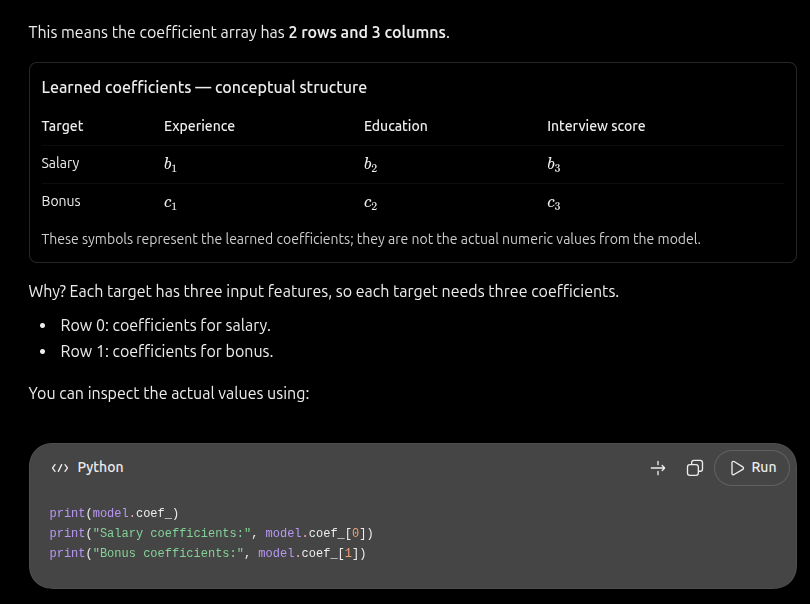

### B. `model.intercept_.shape`

```
print(model.intercept_.shape)
```

Output:

```
(2,)
```

This means the model has two intercept values:

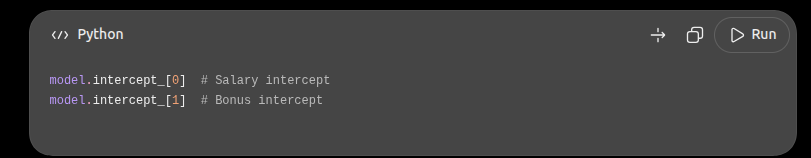

Each target has its own equation and therefore its own intercept.

## 2. Calculate training predictions

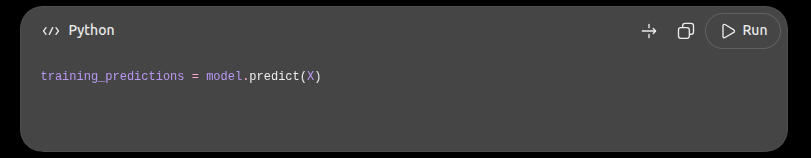

What does this line do?

It asks the trained model to predict the targets for all five observations already present in `X`.

Recall that `X` contains five candidates and `y` contains their actual salaries and bonuses.

Input: `X`

5 candidates × 3 features

Trained model

Uses the learned coefficients and intercepts

Output: `training_predictions`

5 candidates × 2 predicted targets

Check the result:

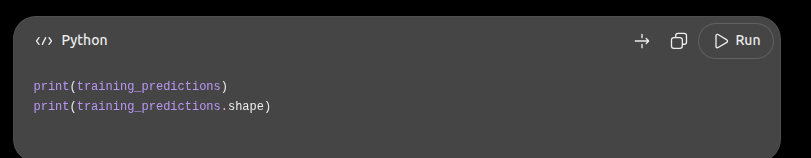

The shape will be:

```
(5, 2)
```

Each row contains the predicted salary and predicted bonus for one candidate.


## Practical 4: Linear Regression using Gradient Descent

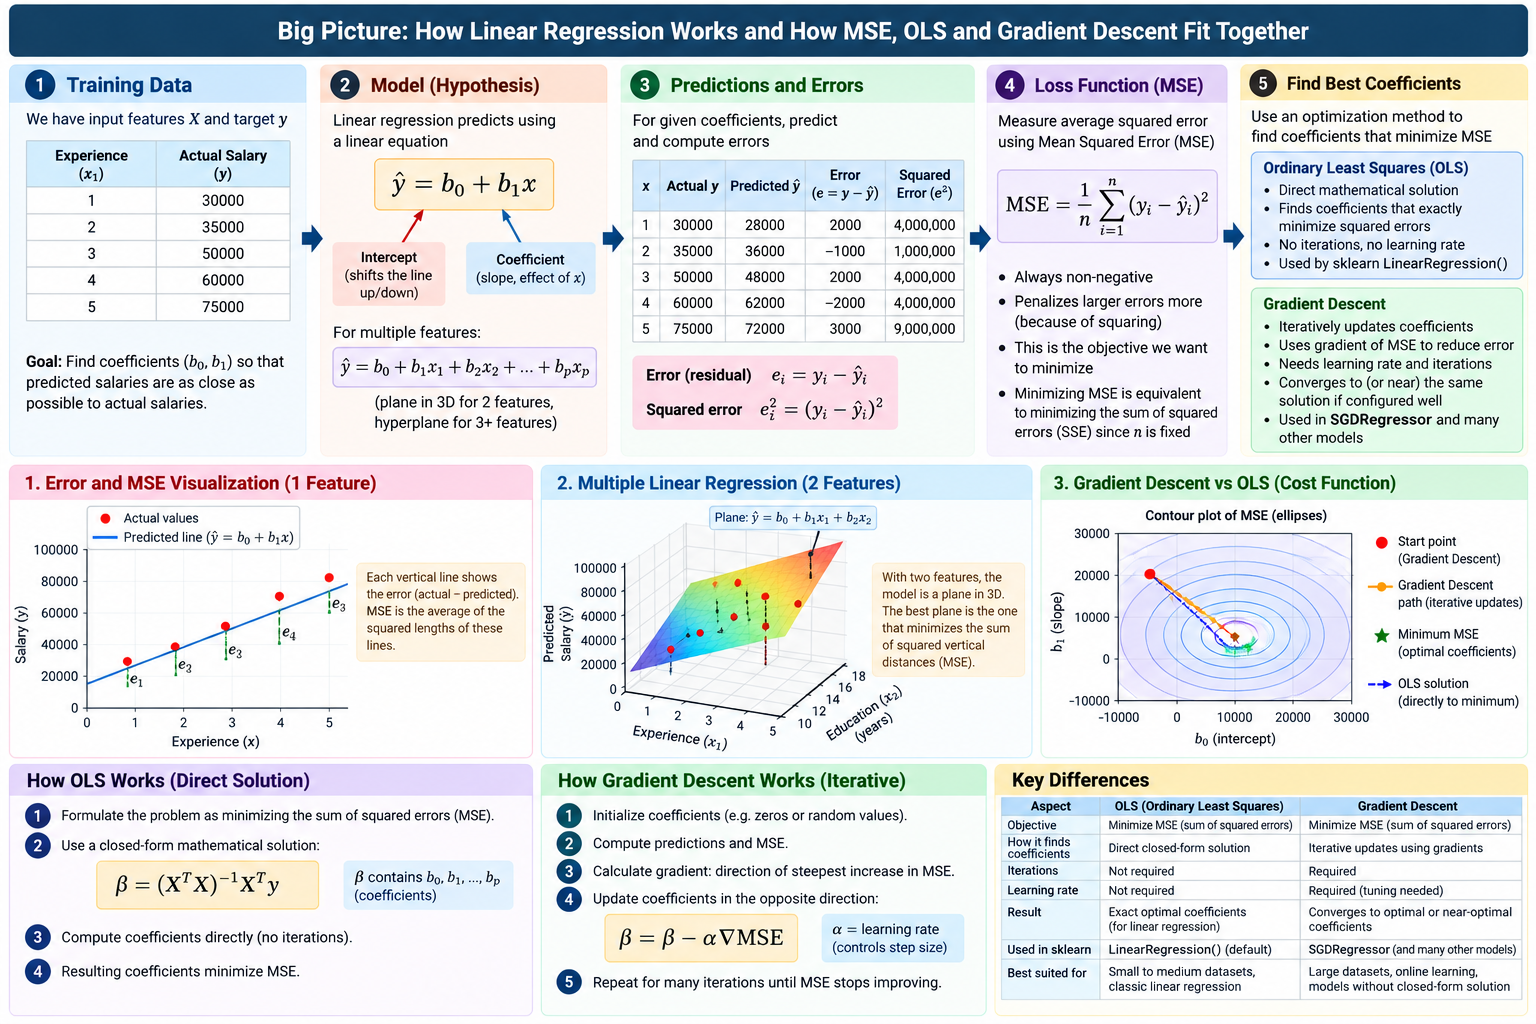

In [37]:

# Import Scikit-learn's regression model that uses Gradient Descent
from sklearn.linear_model import SGDRegressor

# Import Scikit-learn's function to calculate Mean Squared Error (MSE)
from sklearn.metrics import mean_squared_error


# X contains the input feature: years of experience
# Each inner list represents one employee.
# Scikit-learn expects X to be a 2D structure: rows = employees, columns = features.
X = [[1], [2], [3], [4], [5]]

# y contains the actual salary for each employee.
# The salary at position 0 corresponds to the experience at position 0, and so on.
y = [25000, 30000, 35000, 40000, 45000]


# Create a Linear Regression model trained using Stochastic Gradient Descent.
# At this point, the model has NOT learned anything from our training data.
# random_state=42 makes the model's random behavior reproducible.
model = SGDRegressor(random_state=42)


# Train the model using the input features (X) and actual salaries (y).
# Internally, Gradient Descent updates the model's coefficients to reduce prediction error.
# The default training settings are used because we have not specified other parameters.
model.fit(X, y)


# Use the trained model to predict salaries for the same employees in X.
# These are predictions, not the original actual salaries.
predictions = model.predict(X)


# Calculate Mean Squared Error by comparing actual salaries with predicted salaries.
# MSE = average of (actual salary - predicted salary) squared.
# Lower MSE means smaller squared errors on these records.
mse = mean_squared_error(y, predictions)


# Display the model's predicted salaries.
print("Predictions:", predictions)

# Display the average squared prediction error.
print("MSE:", mse)


Predictions: [21737.88733504 27982.03470101 34226.18206697 40470.32943294
 46714.4767989 ]
MSE: 3694599.529945402


/home/amarjeet/projects/ai-env/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


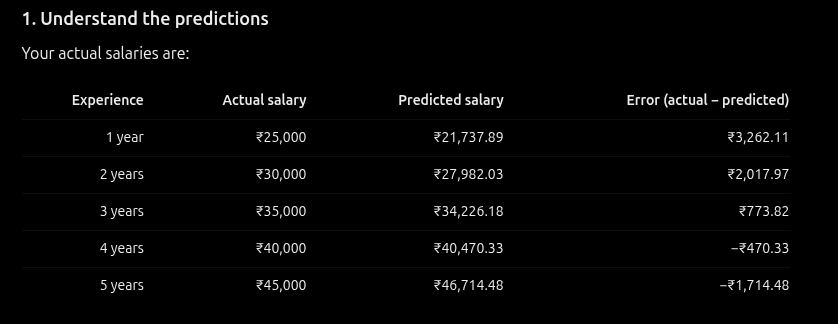

## Start from here tommorow
How do we evaluate the performance of a Regression model, and when should we use MSE, RMSE, or MAE?